In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

In [3]:
from PIL import Image

In [4]:
DATA_DIR = Path("../data/data").resolve()

In [5]:
mask_dirs = sorted(
    path for path in  DATA_DIR.iterdir()
    if path.is_dir()
)

In [6]:
for mask_dir in mask_dirs:
    images = list(mask_dir.glob("*.jpg"))
    print(f"{mask_dir.name}: {len(images)} images")

print("\nTotal group:", len(mask_dirs))

with_mask: 3725 images
without_mask: 3828 images

Total group: 2


In [7]:
X = []
y = []

IMAGE_SIZE = (224, 224)

for mask_dir in mask_dirs:

    mask_name = mask_dir.name

    image_paths = sorted([
        *mask_dir.glob("*.jpg"),
        *mask_dir.glob("*.jpeg"),
        *mask_dir.glob("*.JPG"),
        *mask_dir.glob("*.JPEG")
    ])

    for image_path in image_paths:
        try:
            with Image.open(image_path) as image:
                image = image.convert("RGB")
                image = image.resize(IMAGE_SIZE)

                X.append(np.array(image))
                y.append(mask_name)

        except Exception as error:
            print(f"Could not load {image_path}: {error}")

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of classes:", len(np.unique(y)))

C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


X shape: (15106, 224, 224, 3)
y shape: (15106,)
Number of classes: 2


In [8]:
class_counts = pd.Series(y).value_counts().sort_index()

print(class_counts)
print("\nMinimum images per class:", class_counts.min())
print("Maximum images per class:", class_counts.max())
print("Total images:", class_counts.sum())

with_mask       7450
without_mask    7656
Name: count, dtype: int64

Minimum images per class: 7450
Maximum images per class: 7656
Total images: 15106


In [9]:
import tensorflow as tf

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [11]:
X = X.astype("float32") / 255.0

In [12]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

In [13]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [14]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [15]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Classes:", label_encoder.classes_)

Train: (10574, 224, 224, 3)
Validation: (2266, 224, 224, 3)
Test: (2266, 224, 224, 3)
Classes: ['with_mask' 'without_mask']


In [16]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

In [17]:
model = Sequential([
    Input(shape=(224, 224, 3)),

    # Block 1
    Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=2),

    # Block 2
    Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=2),

    # Block 3
    Conv2D(128, kernel_size=3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=2),

    # Block 4
    Conv2D(256, kernel_size=3, padding="same", activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=2),

    # Feature extraction
    GlobalAveragePooling2D(),

    # Classification
    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(1, activation="sigmoid")
])


In [18]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [21]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

In [22]:


callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        "best_cnn_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]



In [23]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
661/661 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7706 - auc: 0.8472 - loss: 0.4878 - precision: 0.7950 - recall: 0.7375
Epoch 1: val_loss improved from None to 0.57401, saving model to best_cnn_model.keras

Epoch 1: finished saving model to best_cnn_model.keras
661/661 ━━━━━━━━━━━━━━━━━━━━ 1245s 2s/step - accuracy: 0.7706 - auc: 0.8472 - loss: 0.4878 - precision: 0.7950 - recall: 0.7375 - val_accuracy: 0.6659 - val_auc: 0.7569 - val_loss: 0.5740 - val_precision: 0.6802 - val_recall: 0.6429 - learning_rate: 0.0010
Epoch 2/40
661/661 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8918 - auc: 0.9545 - loss: 0.2736 - precision: 0.8931 - recall: 0.8935
Epoch 2: val_loss did not improve from 0.57401
661/661 ━━━━━━━━━━━━━━━━━━━━ 1832s 3s/step - accuracy: 0.8918 - auc: 0.9545 - loss: 0.2736 - precision: 0.8931 - recall: 0.8935 - val_accuracy: 0.5088 - val_auc: 0.6566 - val_loss: 1.8809 - val_precision: 0.8723 - val_recall: 0.0357 - learning_rate: 0.0010
Epoch 3/40
661/661 ━━━━━━

In [24]:
test_results = model.evaluate(X_test, y_test, verbose=1)

for metric_name, metric_value in zip(model.metrics_names, test_results):
    print(f"{metric_name}: {metric_value:.4f}")

71/71 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.9974 - auc: 0.9995 - loss: 0.0111 - precision: 0.9974 - recall: 0.9974
loss: 0.0111
compile_metrics: 0.9974


In [25]:
from sklearn.metrics import classification_report, confusion_matrix

In [26]:
y_pred_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_pred_prob >= 0.5).astype(int)

In [27]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_.astype(str),
        zero_division=0
    )
)

              precision    recall  f1-score   support

   with_mask       1.00      1.00      1.00      1117
without_mask       1.00      1.00      1.00      1149

    accuracy                           1.00      2266
   macro avg       1.00      1.00      1.00      2266
weighted avg       1.00      1.00      1.00      2266



In [28]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[1114    3]
 [   3 1146]]


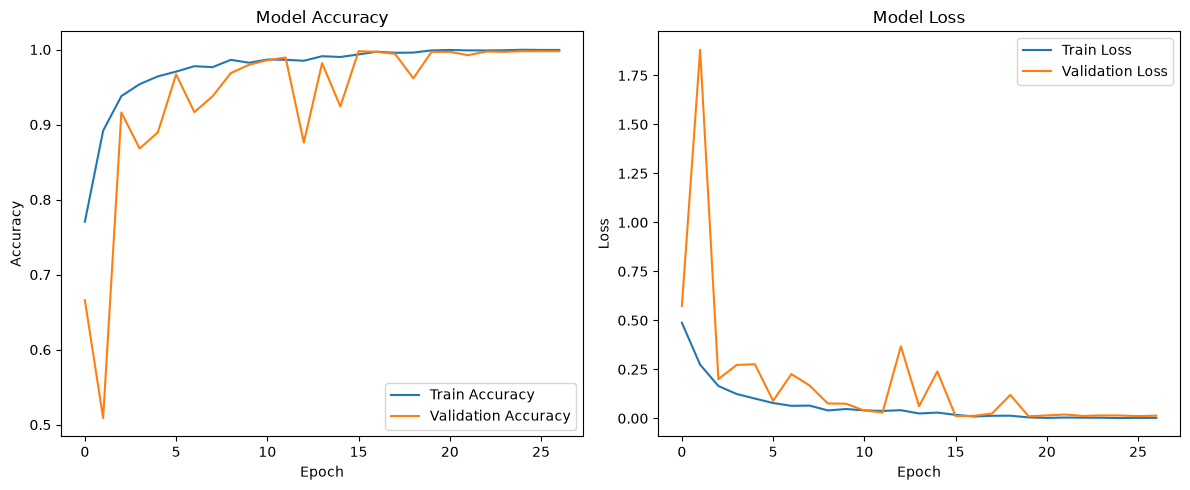

In [29]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()